<a href="https://colab.research.google.com/github/OJB-Quantum/MuMax3-How-To/blob/main/MuMax%20Notebooks/Skyrmion_Racetrack_MuMaxPlus.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
! echo "This machine runs" $(uname) "with" $(python --version) "and provides the following GPU/CUDA specs:"
! nvidia-smi

In [ ]:
!uv pip install mumaxplus matplotlib numpy

minimizing...
running...


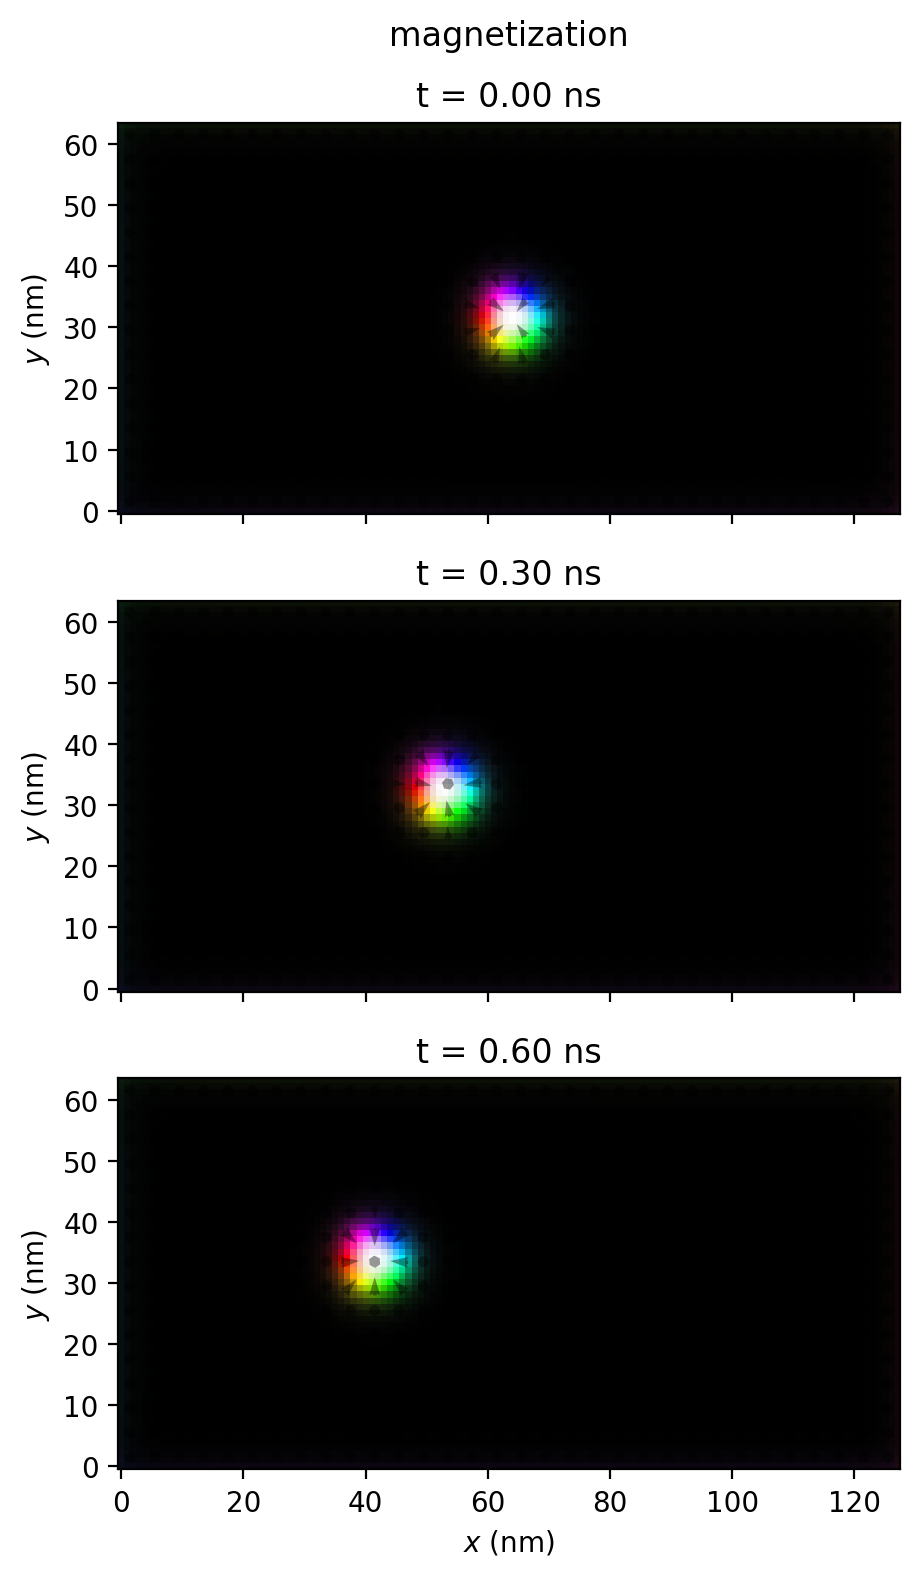

In [3]:
import matplotlib.pyplot as plt

from mumaxplus import Ferromagnet, Grid, World
from mumaxplus.util import neelskyrmion, plot_field

plt.rcParams["figure.dpi"] = 200

# create the world
cellsize = (1e-9, 1e-9, 0.4e-9)
world = World(cellsize)

# create the ferromagnet
nx, ny, nz = 128, 64, 1
magnet = Ferromagnet(world, Grid(size=(nx, ny, nz)))
magnet.enable_demag = False
magnet.msat = 580e3
magnet.aex = 15e-12
magnet.ku1 = 0.8e6
magnet.anisU = (0, 0, 1)
magnet.alpha = 0.2
magnet.dmi_tensor.set_interfacial_dmi(3.2e-3)

# set and relax the initial magnetization
magnet.magnetization = neelskyrmion(
    position=(64e-9, 32e-9, 0), radius=5e-9, charge=-1, polarization=1
)

fig, axs = plt.subplots(nrows=3, sharex="all", sharey="all", figsize=(6, 8))
fig.suptitle("magnetization")
def time_string(): return f"t = {world.timesolver.time*1e9:.2f} ns"
plot_kwrargs = {"arrow_size": 4, "quiver_kwargs": {"width": 2e-9, "units": "xy"}}

print("minimizing...")
magnet.minimize()
plot_field(magnet.magnetization, ax=axs[0], title=time_string(), xlabel="", **plot_kwrargs)

# add a current
magnet.xi = 0.3
magnet.jcur = (1e12, 0, 0)
magnet.pol = 0.4

print("running...")
world.timesolver.run(3e-10)
plot_field(magnet.magnetization, ax=axs[1], title=time_string(), xlabel="", **plot_kwrargs)
world.timesolver.run(3e-10)
plot_field(magnet.magnetization, ax=axs[2], title=time_string(), **plot_kwrargs)

fig.tight_layout()

plt.show()